## Combination Visualization

Combining multiple plots into a single visual representation is a cornerstone of advanced data visualization. While simple charts excel at conveying individual data aspects, complex analytical tasks require examining relationships, distributions, and trends simultaneously.

### Why Combine Plots?
1. **Context and Depth:** Presenting different views (like a main trend line alongside stacked category compositions, or marginal distributions adjacent to scatter plots) provides immediate context without requiring the viewer to toggle between separate figures.
2. **Correlative Insights:** Laying variables out together makes it easier to spot underlying patterns, correlations, and anomalies that isolated plots might obscure.
3. **Visual Efficiency:** It maximizes information density and reduces the cognitive load of stitching together disparate charts from different parts of a report or notebook.

In [9]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# Generate sample data
n_records = 100
categories = ['Electronics', 'Clothing', 'Home & Kitchen', 'Books']
countries = ['USA', 'Canada', 'UK', 'Germany']

data = {
    'Date': pd.date_range(start='2023-01-01', periods=n_records, freq='D'),
    'Category': np.random.choice(categories, size=n_records),
    'Country': np.random.choice(countries, size=n_records),
    'Revenue': np.random.uniform(100, 1000, size=n_records).round(2),
    'Units_Sold': np.random.randint(1, 20, size=n_records),
    'Satisfaction': np.random.uniform(1, 5, size=n_records).round(1)
}

# Create DataFrame
df = pd.DataFrame(data)

# Create a logical Profit column (correlated with Revenue)
df['Profit'] = (df['Revenue'] * np.random.uniform(0.1, 0.4, size=n_records)).round(2)

print("Sample dataset initialized successfully!")
display(df.head())

Sample dataset initialized successfully!


,Date,Category,Country,Revenue,Units_Sold,Satisfaction,Profit
0,2023-01-01,Home & Kitchen,UK,128.29,11,3.1,48.65
1,2023-01-02,Books,Canada,672.77,17,4.1,240.53
2,2023-01-03,Electronics,Canada,382.92,8,1.9,87.57
3,2023-01-04,Home & Kitchen,Germany,557.71,4,3.5,181.40
4,2023-01-05,Home & Kitchen,Canada,916.81,6,1.3,299.21


### Histogram with KDE Plot

A **Histogram with Kernel Density Estimate (KDE)** is used to visualize the distribution of a single continuous variable. The bars represent the frequency of values falling within specific intervals (bins), while the smooth KDE curve estimates the underlying probability density function, helping you easily identify skewness, unimodality, or multimodality.

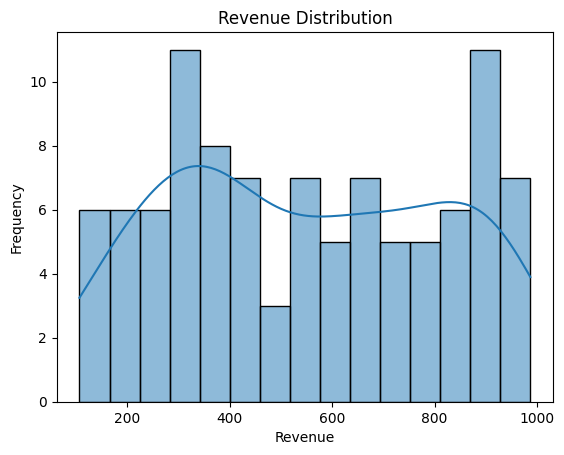

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# Histogram with KDE
sns.histplot(
    data=df,
    x='Revenue',
    bins=15,
    kde=True
)

plt.title('Revenue Distribution')
plt.xlabel('Revenue')
plt.ylabel('Frequency')
plt.show()

## Regression Plots

A **Regression Plot (lmplot)** shows the relationship between two continuous variables along with a fitted linear regression model line. By utilizing `hue` and splitting columns (`col`), we can observe how this relationship differs across categorical groups (like product categories) or regions (like different countries).

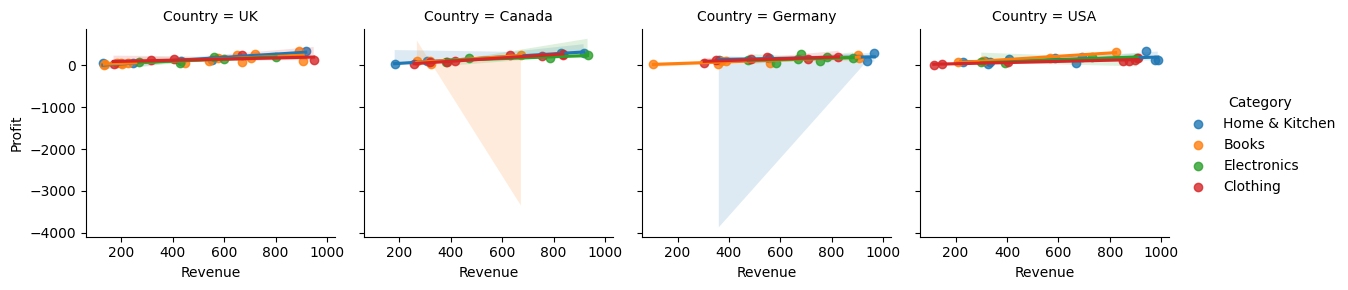

In [11]:
# Regression plots with hue and col
sns.lmplot(
    data=df,
    x='Revenue',
    y='Profit',
    hue='Category',
    col='Country',
    height=3
)

plt.show()

## Bar and Line Combination Plots

A **Combination Plot (Bar + Line)** is ideal for showing both composition and overall progression over time. In this plot, stacked bar charts show the breakdown of monthly revenue across categories, while a line chart plotted on a secondary y-axis shows the overall monthly revenue trend.

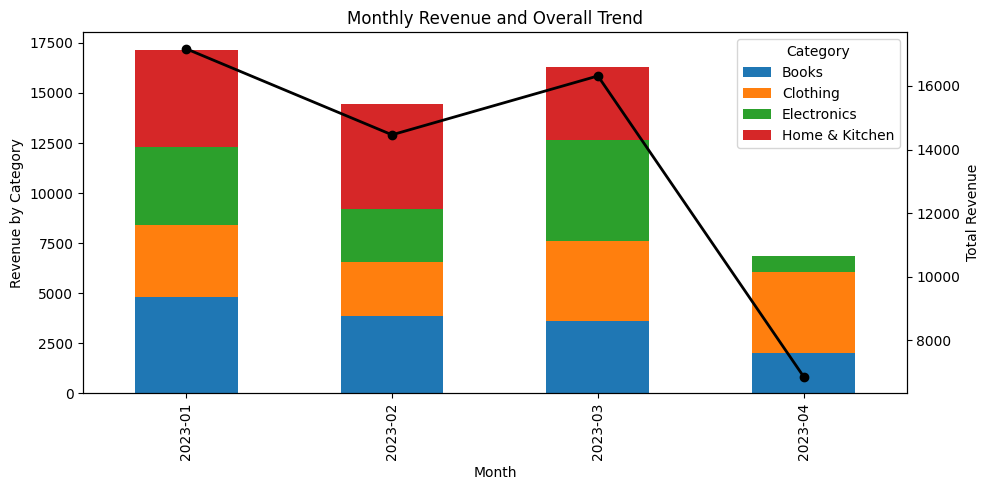

In [12]:
# Prepare monthly revenue by category
df['Month'] = df['Date'].dt.to_period('M').astype(str)

monthly_revenue = df.pivot_table(
    index='Month',
    columns='Category',
    values='Revenue',
    aggfunc='sum',
    fill_value=0
)

monthly_total = monthly_revenue.sum(axis=1)

fig, ax1 = plt.subplots(figsize=(10, 5))

# Stacked bars
monthly_revenue.plot(
    kind='bar',
    stacked=True,
    ax=ax1
)

ax1.set_xlabel('Month')
ax1.set_ylabel('Revenue by Category')
ax1.set_title('Monthly Revenue and Overall Trend')

# Overall total line on a second axis
ax2 = ax1.twinx()

ax2.plot(
    range(len(monthly_total)),
    monthly_total.values,
    color='black',
    marker='o',
    linewidth=2,
    label='Total Revenue'
)

ax2.set_ylabel('Total Revenue')

plt.tight_layout()
plt.show()

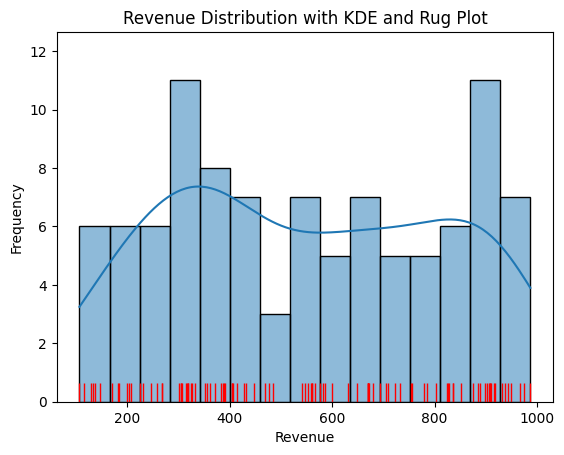

In [13]:
# Histogram + KDE + Rug Plot
sns.histplot(
    data=df,
    x='Revenue',
    bins=15,
    kde=True
)

sns.rugplot(
    data=df,
    x='Revenue',
    color='red',
    height=0.05
)

plt.title('Revenue Distribution with KDE and Rug Plot')
plt.xlabel('Revenue')
plt.ylabel('Frequency')
plt.show()

## Pair Plot

A **Pair Plot** visualizes pairwise relationships in a dataset. It plots a grid of pairwise scatter plots for the specified continuous variables, alongside univariate distribution plots (like KDEs) along the diagonal. Color-coding by a categorical feature helps detect clusters, trends, and correlations across multiple dimensions.

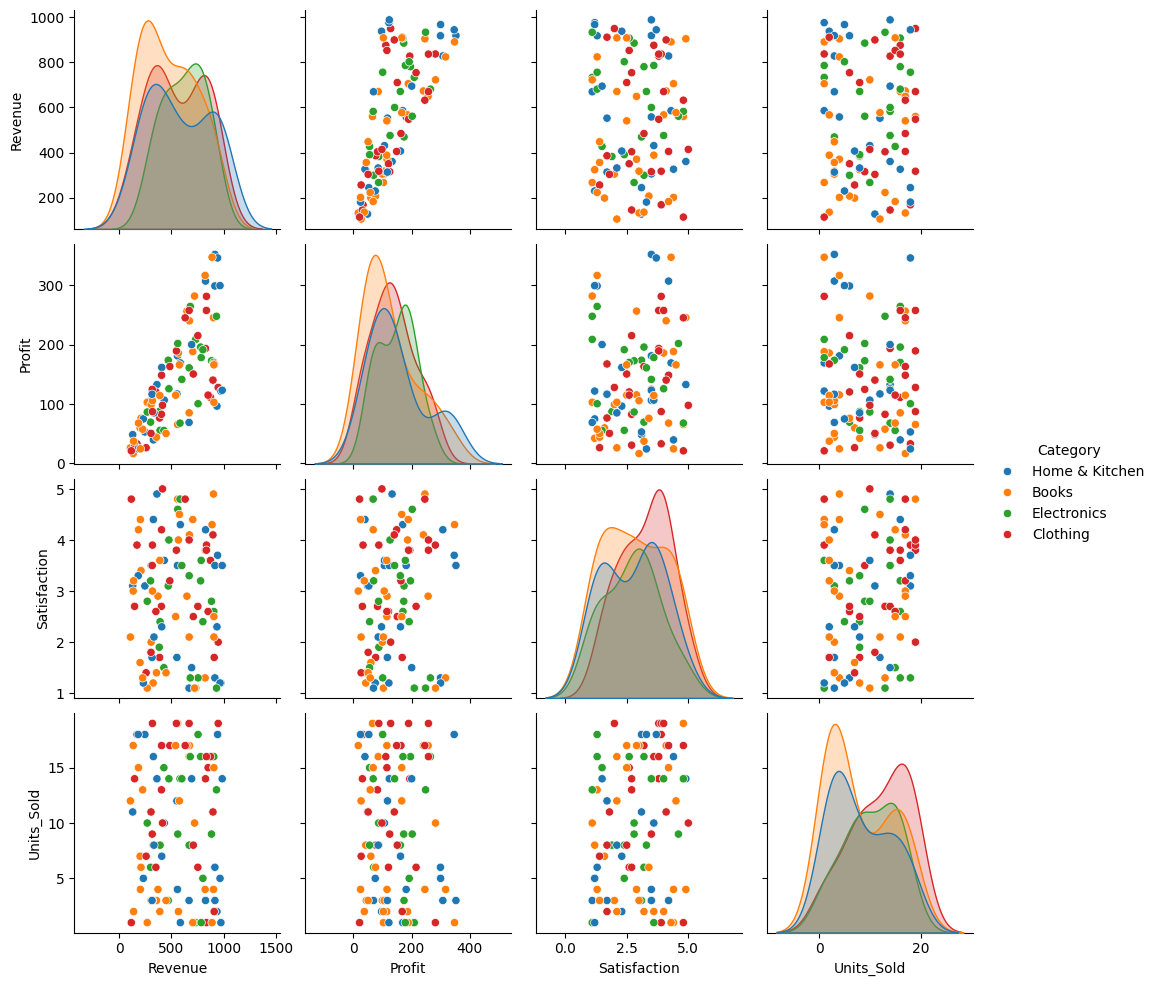

In [14]:
# Pair Plot
sns.pairplot(
    data=df,
    vars=[
        'Revenue',
        'Profit',
        'Satisfaction',
        'Units_Sold'
    ],
    hue='Category'
)

plt.show()

## Joint Plot

A **Joint Plot** combines a bivariate plot (such as a scatter plot with a regression line) showing the relationship between two variables, with univariate plots (histograms or density curves) of each individual variable along the margins. This gives a comprehensive view of both joint and marginal distributions.

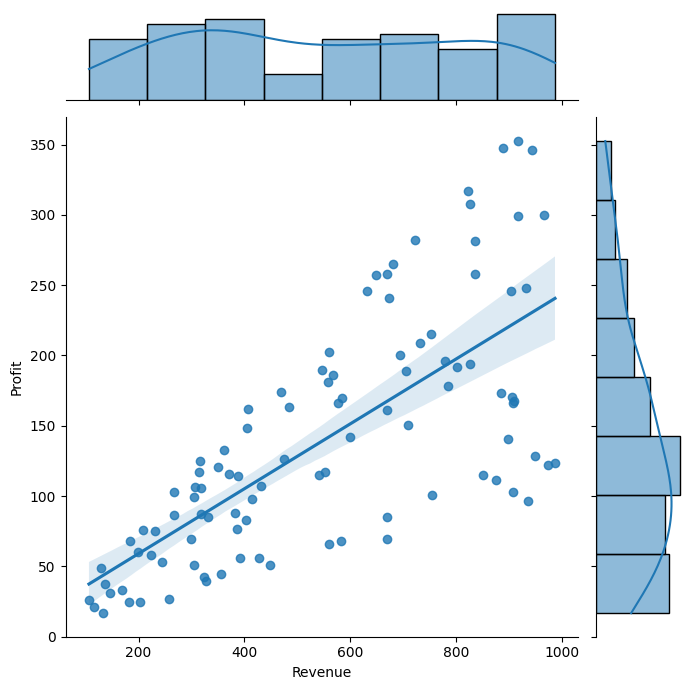

In [15]:
# Joint Plot
sns.jointplot(
    data=df,
    x='Revenue',
    y='Profit',
    kind='reg',
    height=7
)

plt.show()